# 20 · Circuits exact

**Question.** Is each form's circuit the operator that was assembled classically: does the stacked reflection V encode 2H/α_R² − I exactly?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p3_pillar1", "p5_encode")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p3_pillar1: 104 records, 104 ok
p5_encode: 60 records, 60 ok


In [2]:
from IPython.display import Markdown, display

forms = {
    form: [r for r in results.rows(name) if r["status"] == "ok"]
    for form, name in (("standard", "p3_pillar1"), ("descriptor", "p5_encode"))
}
exact = {form: [r for r in rows if r["verify_mode"] == "exact"] for form, rows in forms.items()}


def verdict(form):
    """Return one line: the exact verifications, their worst error, and the widest circuit."""
    checked = exact[form]
    passed = sum(r["verify_passed"] is True for r in checked)
    worst = max(r["verify_max_error"] / r["verify_tolerance"] for r in checked)
    return (
        f"- The {form} form: {passed} of {len(checked)} exact verifications pass, on up to "
        f"{max(r['n_qubits_total'] for r in checked)} qubits; the largest error is "
        f"{max(r['verify_max_error'] for r in checked):.1e}, and none exceeds {worst:.1e} of its "
        "tolerance; "
        f"{len(forms[form]) - len(checked)} records are construction only."
    )


display(Markdown("\n".join(verdict(form) for form in forms)))

- The standard form: 54 of 54 exact verifications pass, on up to 25 qubits; the largest error is 5.9e-15, and none exceeds 5.9e-05 of its tolerance; 50 records are construction only.
- The descriptor form: 26 of 26 exact verifications pass, on up to 19 qubits; the largest error is 3.7e-15, and none exceeds 3.7e-05 of its tolerance; 34 records are construction only.

Each exact verification's largest entry error, V's block against 2H/α_R² − I assembled
independently, one statevector evolution per basis state, by the circuit's total qubits. The
dashed line is the tightest tolerance any record was held to.

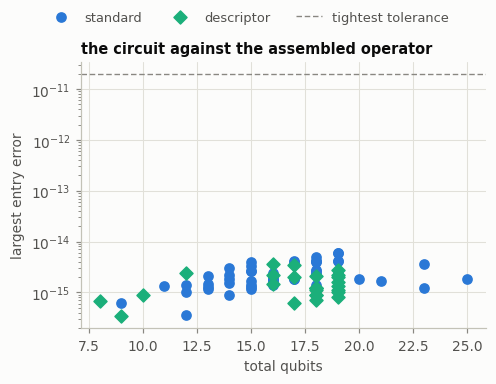

In [3]:
plotting.checks(
    [
        plotting.Check(
            exact,
            "n_qubits_total",
            "verify_max_error",
            "total qubits",
            "largest entry error",
            "the circuit against the assembled operator",
            diagonal=False,
            bar=min(r["verify_tolerance"] for rows in exact.values() for r in rows),
            bar_label="tightest tolerance",
            logx=False,
        )
    ]
);

**What this does not show.** Exact verification stops where a statevector per basis state no
longer fits; beyond it the records are construction only, and the parts are verified by the
test suite, with the IR mode at every n. The circuits' building blocks are verified by the tests,
not by records.